In [3]:
import os
import random
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader


from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

from tqdm.auto import tqdm



In [4]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Устройство:", DEVICE)

if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Устройство: cpu


In [ ]:
TRAIN_PATH = "train_for3_1.npz"
TEST_PATH = "test_features_for3_1.npz"

train_data = np.load(TRAIN_PATH)
test_data = np.load(TEST_PATH)

X = train_data["images"]
y = train_data["prediction"]

train_ids = train_data["image_id"]

X_test = test_data["images"]
test_ids = test_data["image_id"]

class_names = train_data["label_names"]

NUM_CLASSES = len(class_names)

print("TRAIN:")
print("Images:", X.shape)
print("Labels:", y.shape)

print("\nTEST:")
print("Images:", X_test.shape)
print("IDs:", test_ids.shape)



TRAIN:
Images: (7200, 28, 28, 3)
Labels: (7200,)

TEST:
Images: (1800, 28, 28, 3)
IDs: (1800,)

Количество классов: 9


In [ ]:

print("Минимальное значение:", X.min())
print("Максимальное значение:", X.max())

print("\nКоличество уникальных классов:", len(np.unique(y)))
print("Количество уникальных train ID:", len(np.unique(train_ids)))
print("Количество уникальных test ID:", len(np.unique(test_ids)))

assert X.shape[1:] == (28, 28, 3)
assert X_test.shape[1:] == (28, 28, 3)
assert len(X) == len(y) == len(train_ids)
assert len(X_test) == len(test_ids)
assert len(np.unique(train_ids)) == len(train_ids)
assert len(np.unique(test_ids)) == len(test_ids)

assert np.isin(y, np.arange(NUM_CLASSES)).all()

Тип изображений: uint8
Минимальное значение: 0
Максимальное значение: 255

Количество уникальных классов: 9
Количество уникальных train ID: 7200
Количество уникальных test ID: 1800

Проверка успешно пройдена!


,class_id,class_name,count
0,0,adipose,750
1,1,background,761
2,2,debris,829
3,3,lymphocytes,832
4,4,mucus,641
5,5,smooth muscle,974
6,6,normal colon mucosa,631
7,7,cancer-associated stroma,752
8,8,colorectal adenocarcinoma epithelium,1030


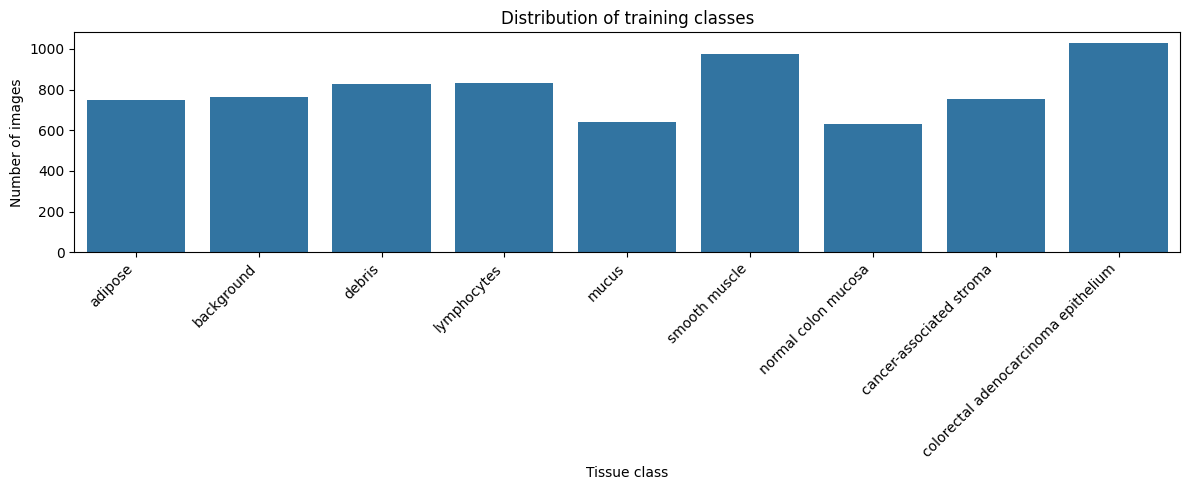

In [7]:
class_counts = pd.Series(y).value_counts().sort_index()

distribution = pd.DataFrame({
    "class_id": range(NUM_CLASSES),
    "class_name": class_names,
    "count": class_counts.values
})

display(distribution)

plt.figure(figsize=(12, 5))

sns.barplot(
    data=distribution,
    x="class_name",
    y="count"
)

plt.xticks(rotation=45, ha="right")
plt.title("Distribution of training classes")
plt.xlabel("Tissue class")
plt.ylabel("Number of images")
plt.tight_layout()
plt.show()

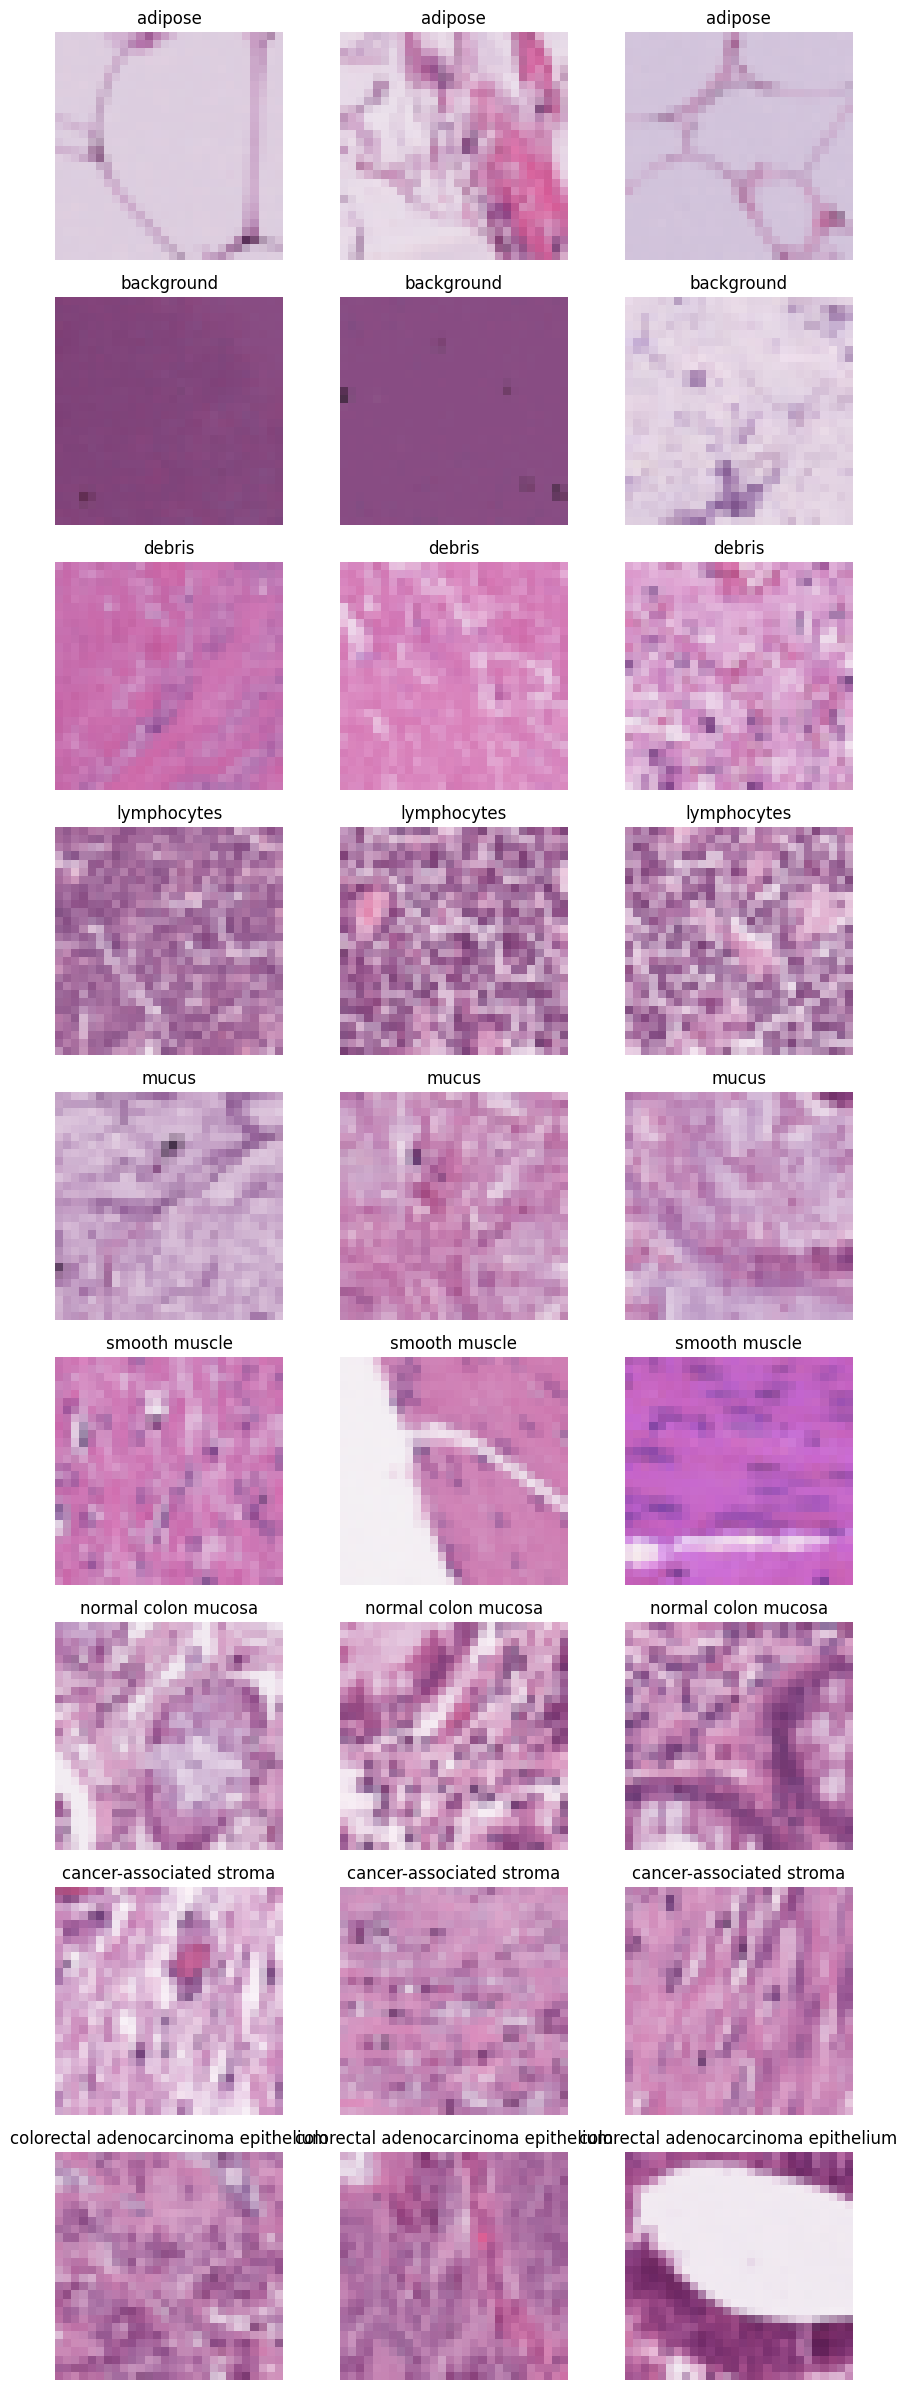

In [8]:
fig, axes = plt.subplots(
    NUM_CLASSES, 3,
    figsize=(9, 24)
)

for class_id in range(NUM_CLASSES):

    indices = np.where(y == class_id)[0]

    selected = np.random.choice(
        indices,
        size=min(3, len(indices)),
        replace=False
    )

    for j, idx in enumerate(selected):

        axes[class_id, j].imshow(X[idx])

        axes[class_id, j].axis("off")

        axes[class_id, j].set_title(
            f"{class_names[class_id]}"
        )

plt.tight_layout()
plt.show()

Среднее значение пикселей: 167.90665243527965
Стандартное отклонение: 43.299993725665665


C:\Temp\ipykernel_26856\1424726881.py:12: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(X.reshape(-1, 3), labels=["R", "G", "B"])


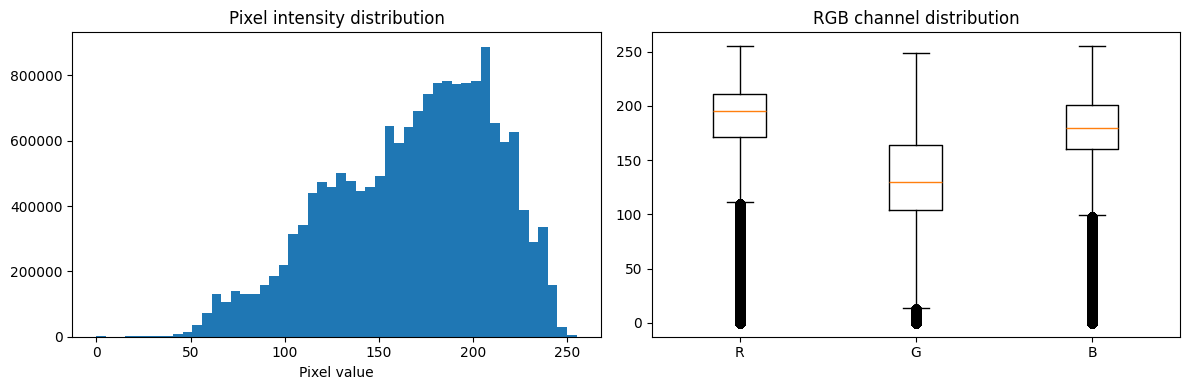

In [9]:
print("Среднее значение пикселей:", X.mean())
print("Стандартное отклонение:", X.std())

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.hist(X.flatten(), bins=50)
plt.title("Pixel intensity distribution")
plt.xlabel("Pixel value")

plt.subplot(1, 2, 2)
plt.boxplot(X.reshape(-1, 3), labels=["R", "G", "B"])
plt.title("RGB channel distribution")

plt.tight_layout()
plt.show()

In [10]:
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=SEED,
    stratify=y
)

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

print("\nРаспределение классов в train:")
print(np.bincount(y_train))

print("\nРаспределение классов в validation:")
print(np.bincount(y_val))

Train: (5760, 28, 28, 3)
Validation: (1440, 28, 28, 3)
Test: (1800, 28, 28, 3)

Распределение классов в train:
[600 609 663 666 513 779 505 601 824]

Распределение классов в validation:
[150 152 166 166 128 195 126 151 206]


In [11]:
X_train_float = X_train.astype(np.float32) / 255.0

CHANNEL_MEAN = X_train_float.mean(axis=(0, 1, 2))
CHANNEL_STD = X_train_float.std(axis=(0, 1, 2))

print("Mean:", CHANNEL_MEAN)
print("Std:", CHANNEL_STD)

Mean: [0.7363457 0.530634  0.7081155]
Std: [0.12334582 0.17477502 0.12328921]


In [12]:
class HistopathologyDataset(Dataset):

    def __init__(
        self,
        images,
        labels=None,
        mean=None,
        std=None,
        augment=False
    ):

        self.images = images
        self.labels = labels

        self.mean = torch.tensor(
            mean, dtype=torch.float32
        ).view(3, 1, 1)

        self.std = torch.tensor(
            std, dtype=torch.float32
        ).view(3, 1, 1)

        self.augment = augment

    def __len__(self):

        return len(self.images)

    def __getitem__(self, idx):

        image = self.images[idx]

        image = torch.from_numpy(
            image.copy()
        ).permute(2, 0, 1).float() / 255.0

        if self.augment:

            if random.random() > 0.5:
                image = torch.flip(image, dims=[2])

            if random.random() > 0.5:
                image = torch.flip(image, dims=[1])

            k = random.randint(0, 3)

            image = torch.rot90(
                image,
                k=k,
                dims=[1, 2]
            )

        image = (
            image - self.mean
        ) / self.std.clamp(min=1e-6)

        if self.labels is not None:

            label = int(self.labels[idx])

            return image, label

        return image

In [13]:
BATCH_SIZE = 128

train_dataset = HistopathologyDataset(
    X_train,
    y_train,
    CHANNEL_MEAN,
    CHANNEL_STD,
    augment=True
)

val_dataset = HistopathologyDataset(
    X_val,
    y_val,
    CHANNEL_MEAN,
    CHANNEL_STD,
    augment=False
)

test_dataset = HistopathologyDataset(
    X_test,
    labels=None,
    mean=CHANNEL_MEAN,
    std=CHANNEL_STD,
    augment=False
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=(DEVICE.type == "cuda")
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=(DEVICE.type == "cuda")
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=(DEVICE.type == "cuda")
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Train batches: 45
Validation batches: 12
Test batches: 15


In [14]:
class ConvBlock(nn.Module):

    def __init__(self, in_channels, out_channels):

        super().__init__()

        self.block = nn.Sequential(

            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=3,
                padding=1,
                bias=False
            ),

            nn.BatchNorm2d(out_channels),

            nn.ReLU(inplace=True),

            nn.Conv2d(
                out_channels,
                out_channels,
                kernel_size=3,
                padding=1,
                bias=False
            ),

            nn.BatchNorm2d(out_channels),

            nn.ReLU(inplace=True),

            nn.MaxPool2d(kernel_size=2)
        )

    def forward(self, x):

        return self.block(x)


class HistopathologyCNN(nn.Module):

    def __init__(self, num_classes=9):

        super().__init__()

        self.features = nn.Sequential(

            ConvBlock(3, 32),

            ConvBlock(32, 64),

            ConvBlock(64, 128),

            ConvBlock(128, 192)

        )

        self.pool = nn.AdaptiveAvgPool2d(1)

        self.classifier = nn.Sequential(

            nn.Flatten(),

            nn.Linear(192, 128),

            nn.ReLU(inplace=True),

            nn.Dropout(0.4),

            nn.Linear(128, num_classes)

        )

    def forward(self, x):

        x = self.features(x)

        x = self.pool(x)

        x = self.classifier(x)

        return x


model = HistopathologyCNN(
    num_classes=NUM_CLASSES
).to(DEVICE)

print(model)

HistopathologyCNN(
  (features): Sequential(
    (0): ConvBlock(
      (block): Sequential(
        (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (5): ReLU(inplace=True)
        (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      )
    )
    (1): ConvBlock(
      (block): Sequential(
        (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), 

In [15]:
total_params = sum(
    p.numel() for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("Всего параметров:", total_params)
print("Обучаемых параметров:", trainable_params)

Всего параметров: 867049
Обучаемых параметров: 867049


In [16]:
EPOCHS = 30

LEARNING_RATE = 0.001

criterion = nn.CrossEntropyLoss()

optimizer = optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=1e-4
)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=3
)

best_val_accuracy = 0.0

PATIENCE = 7

history = {
    "train_loss": [],
    "val_loss": [],
    "train_accuracy": [],
    "val_accuracy": []
}

best_model_state = None
early_stop_counter = 0

In [17]:
def train_one_epoch(model, loader, criterion, optimizer):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in tqdm(loader):

        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        correct += (
            predictions == labels
        ).sum().item()

        total += labels.size(0)

    epoch_loss = running_loss / total

    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy

In [29]:
def validate_one_epoch(model, loader, criterion):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0
    with torch.no_grad():

        for images, labels in loader:

            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)

            correct += (
                predictions == labels
            ).sum().item()

            total += labels.size(0)
    epoch_loss = running_loss / total
    epoch_accuracy = correct / total
    return epoch_loss, epoch_accuracy

In [30]:
for epoch in range(EPOCHS):
    print(f"\nEpoch {epoch + 1}/{EPOCHS}")

    train_loss, train_acc = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer
    )

    val_loss, val_acc = validate_one_epoch(
        model,
        val_loader,
        criterion
    )
    scheduler.step(val_acc)
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_accuracy"].append(train_acc)
    history["val_accuracy"].append(val_acc)
    print(f"Train Loss: {train_loss:.4f}")
    print(f"Train Accuracy: {train_acc:.4f}")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation Accuracy: {val_acc:.4f}")

    print(
        "Learning Rate:",
        optimizer.param_groups[0]["lr"]
    )

    if val_acc > best_val_accuracy:

        best_val_accuracy = val_acc

        best_model_state = copy.deepcopy(
            model.state_dict()
        )

        torch.save(
            best_model_state,
            "best_task3_1_model.pth"
        )

        early_stop_counter = 0

        print("Best model saved!")

    else:

        early_stop_counter += 1

    if early_stop_counter >= PATIENCE:

        print("Early stopping activated.")

        break


model.load_state_dict(best_model_state)



print(
    "Best validation accuracy:",
    round(best_val_accuracy, 4)
)


Epoch 1/30


  0%|          | 0/45 [00:00<?, ?it/s]

Train Loss: 0.1259
Train Accuracy: 0.9580
Validation Loss: 0.1724
Validation Accuracy: 0.9396
Learning Rate: 0.00025

Epoch 2/30


  0%|          | 0/45 [00:00<?, ?it/s]

Train Loss: 0.1164
Train Accuracy: 0.9594
Validation Loss: 0.2176
Validation Accuracy: 0.9278
Learning Rate: 0.000125

Epoch 3/30


  0%|          | 0/45 [00:00<?, ?it/s]

... (39 outputs left out)

  0%|          | 0/45 [00:00<?, ?it/s]

Train Loss: 0.0539
Train Accuracy: 0.9804
Validation Loss: 0.1650
Validation Accuracy: 0.9493
Learning Rate: 3.125e-05

Epoch 24/30


  0%|          | 0/45 [00:00<?, ?it/s]

Train Loss: 0.0491
Train Accuracy: 0.9835
Validation Loss: 0.1636
Validation Accuracy: 0.9507
Learning Rate: 3.125e-05
Early stopping activated.
Best validation accuracy: 0.9542


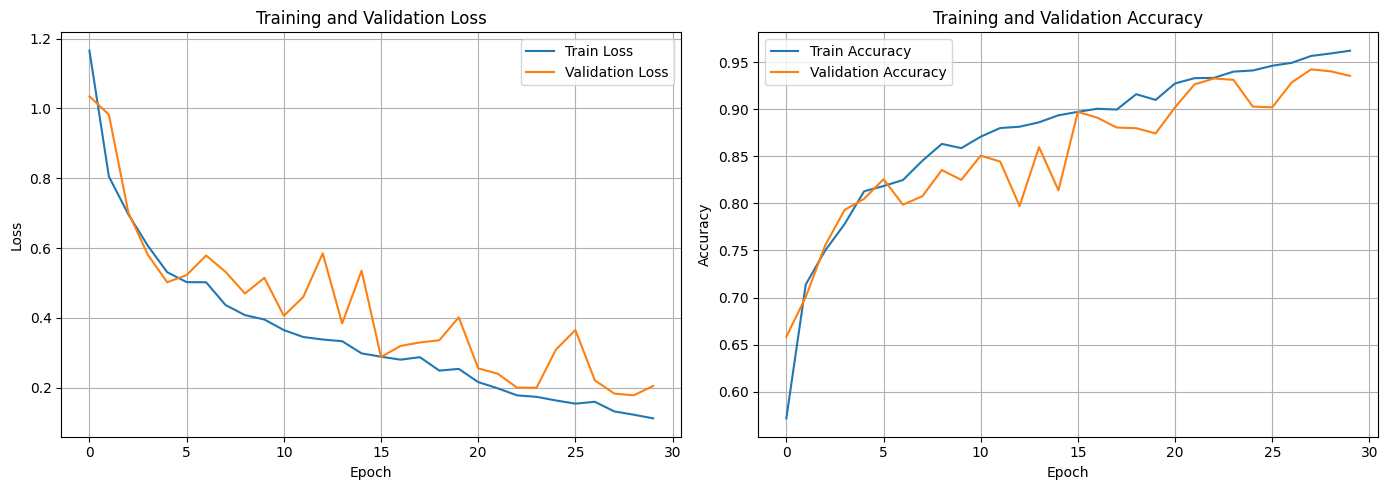

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    history["train_loss"],
    label="Train Loss"
)

axes[0].plot(
    history["val_loss"],
    label="Validation Loss"
)

axes[0].set_title("Training and Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid()

axes[1].plot(
    history["train_accuracy"],
    label="Train Accuracy"
)

axes[1].plot(
    history["val_accuracy"],
    label="Validation Accuracy"
)

axes[1].set_title("Training and Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid()

plt.tight_layout()
plt.show()

In [21]:
model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():

    for images, labels in val_loader:

        images = images.to(DEVICE)

        outputs = model(images)

        predictions = outputs.argmax(dim=1)

        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_labels.extend(
            labels.numpy()
        )

print(
    classification_report(
        all_labels,
        all_predictions,
        labels=list(range(NUM_CLASSES)),
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)

                                      precision    recall  f1-score   support

                             adipose     1.0000    0.9867    0.9933       150
                          background     1.0000    1.0000    1.0000       152
                              debris     0.9608    0.8855    0.9216       166
                         lymphocytes     0.9822    1.0000    0.9910       166
                               mucus     0.9104    0.9531    0.9313       128
                       smooth muscle     0.9836    0.9231    0.9524       195
                 normal colon mucosa     0.8633    0.9524    0.9057       126
            cancer-associated stroma     0.8070    0.9139    0.8571       151
colorectal adenocarcinoma epithelium     0.9634    0.8932    0.9270       206

                            accuracy                         0.9424      1440
                           macro avg     0.9412    0.9453    0.9422      1440
                        weighted avg     0.9458    0.9424    0

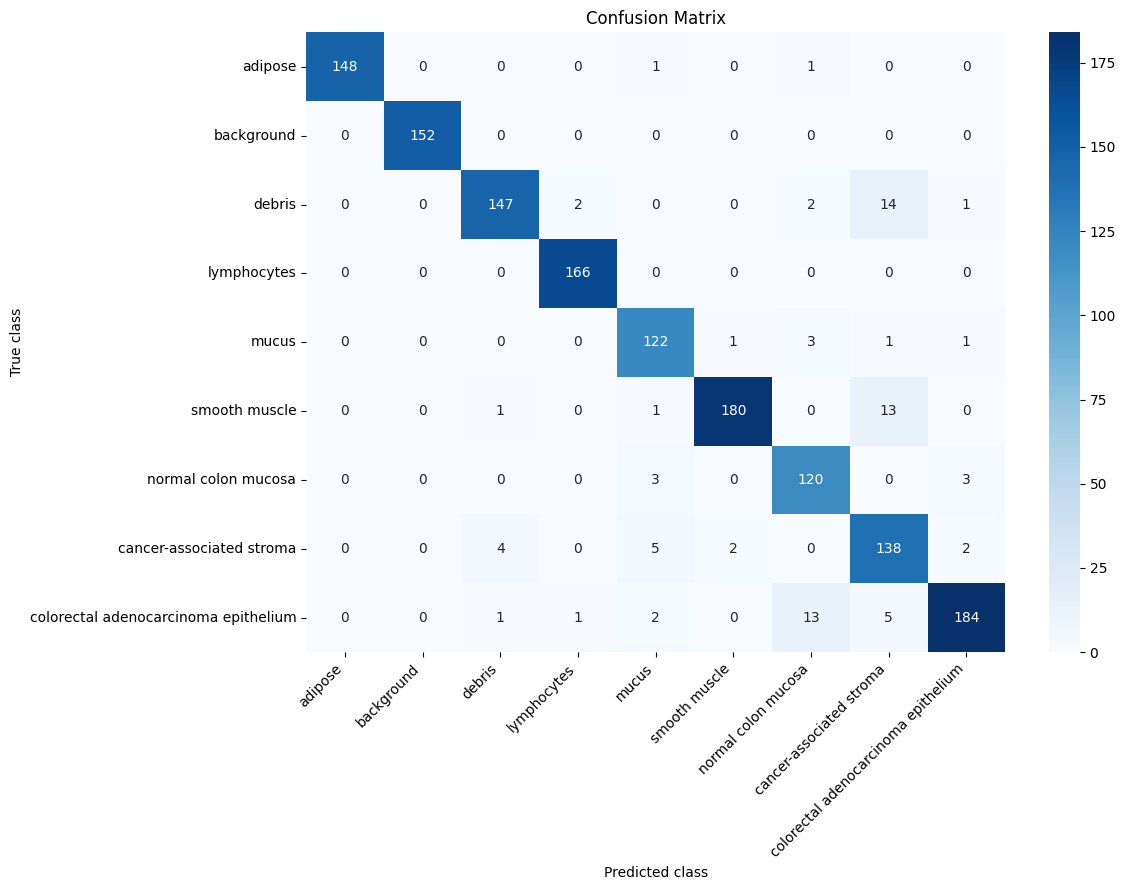

In [22]:
cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=range(NUM_CLASSES)
)

plt.figure(figsize=(12, 9))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted class")
plt.ylabel("True class")

plt.title("Confusion Matrix")

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

In [23]:
model.eval()

test_predictions = []
test_probabilities = []

with torch.no_grad():

    for images in tqdm(test_loader):

        images = images.to(DEVICE)

        outputs = model(images)

        probabilities = torch.softmax(
            outputs,
            dim=1
        )

        predictions = outputs.argmax(dim=1)

        test_predictions.extend(
            predictions.cpu().numpy()
        )

        test_probabilities.extend(
            probabilities.cpu().numpy()
        )


test_predictions = np.array(test_predictions)

test_probabilities = np.array(test_probabilities)

print("Predictions shape:", test_predictions.shape)
print("Probabilities shape:", test_probabilities.shape)

print("Количество предсказаний:", len(test_predictions))

  0%|          | 0/15 [00:00<?, ?it/s]

Predictions shape: (1800,)
Probabilities shape: (1800, 9)
Количество предсказаний: 1800


Средняя уверенность: 0.9493278
Минимальная уверенность: 0.3675119
Максимальная уверенность: 1.0


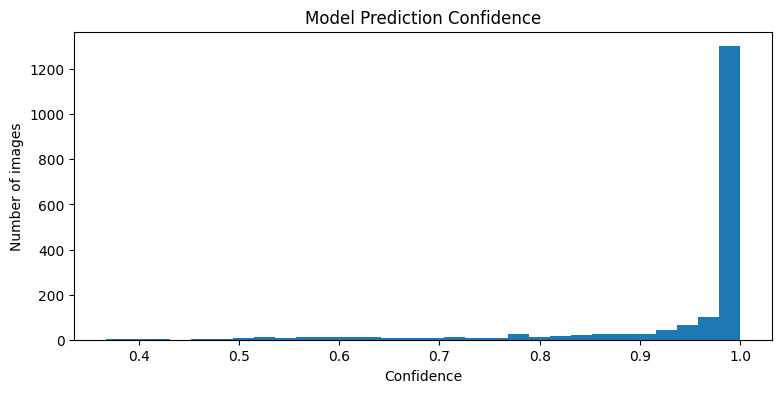

In [24]:
confidence = test_probabilities.max(axis=1)

print("Средняя уверенность:", confidence.mean())
print("Минимальная уверенность:", confidence.min())
print("Максимальная уверенность:", confidence.max())

plt.figure(figsize=(9, 4))

plt.hist(
    confidence,
    bins=30
)

plt.title("Model Prediction Confidence")
plt.xlabel("Confidence")
plt.ylabel("Number of images")

plt.show()

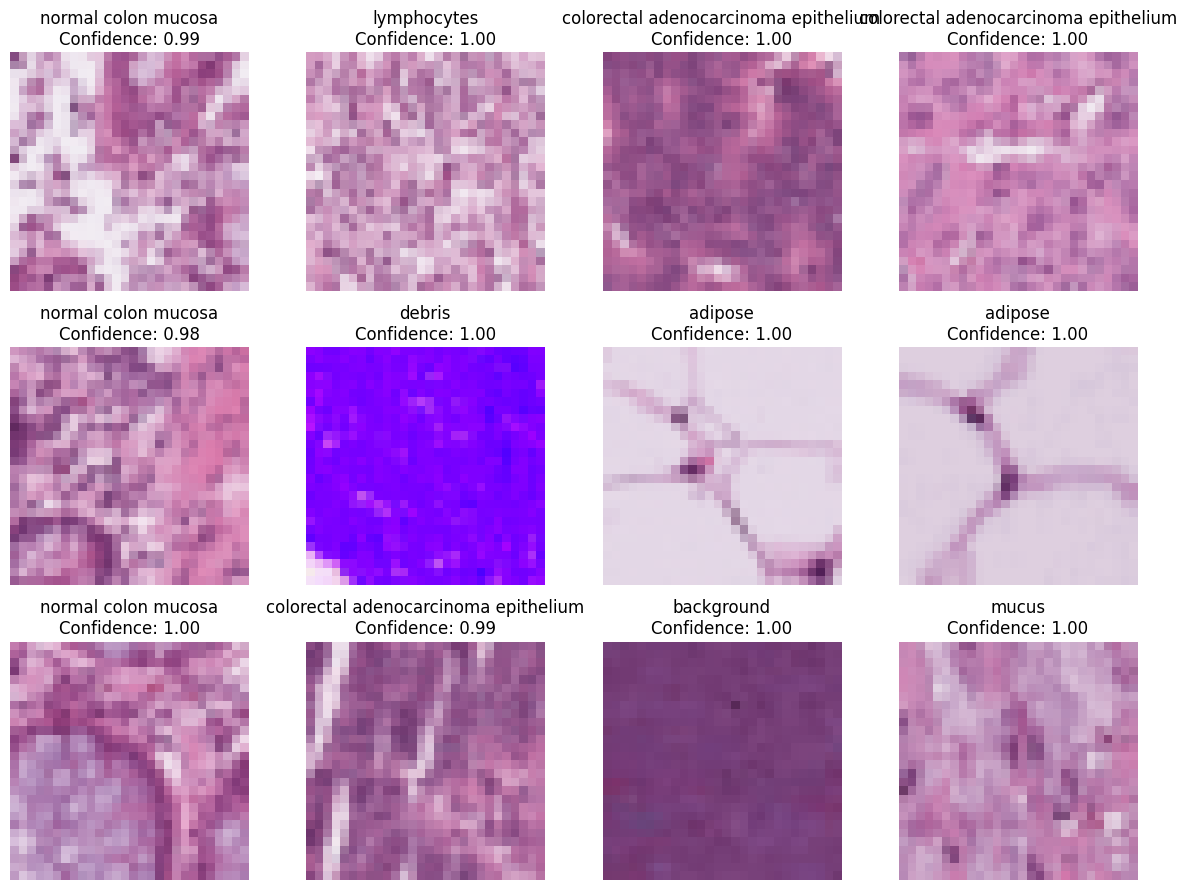

In [25]:
fig, axes = plt.subplots(3, 4, figsize=(12, 9))

indices = np.random.choice(
    len(X_test),
    size=12,
    replace=False
)

for ax, idx in zip(axes.flatten(), indices):

    ax.imshow(X_test[idx])

    predicted_class = test_predictions[idx]

    score = confidence[idx]

    ax.set_title(
        f"{class_names[predicted_class]}\n"
        f"Confidence: {score:.2f}"
    )

    ax.axis("off")

plt.tight_layout()
plt.show()

In [28]:
output_dir = "outputs/task3_1"

os.makedirs(
    output_dir,
    exist_ok=True
)

submission = pd.DataFrame({

    "image_id": test_ids,

    "prediction": test_predictions.astype(int)

})

output_path = os.path.join(
    output_dir,
    "task3_1_predictions.csv"
)

submission.to_csv(
    output_path,
    index=False
)

display(submission.head(10))

,image_id,prediction
0,100,3
1,130,0
2,156,5
3,169,5
4,248,3
5,270,6
6,333,1
7,343,7
8,390,2
9,420,7
